# Credit Risk Exploratory Data Analysis

**Exploratory analysis of 32,581 loan records to understand which borrower and loan characteristics are associated with default**

**Date:** October 13, 2026

## 1. Business context

Lenders need to understand which borrower and loan characteristics are associated with default before approving credit or building a risk model. Before modeling, it is also necessary to check whether the data are complete and plausible.

## 2. Project objective

This project explores a credit risk dataset to:
- assess the structure, completeness and plausibility of the data;
- summarize the distribution of numeric and categorical variables;
- compare default rates across borrower and loan characteristics;
- examine how numeric variables relate to default; and
- identify data-quality issues to address before modeling.

The analysis is descriptive. It identifies associations, not causes.

## 3. Scope and limitations

- The dataset contains 12 variables per loan and no date field, so changes over time cannot be analyzed.
- `loan_status` is the outcome variable (0 = repaid, 1 = default).
- Implausible values (for example, ages above 100 or employment lengths above 100 years) are flagged but retained during the initial exploration.
- Results describe this dataset and should not be generalized to other lenders or populations.

## 4. Dataset source

The file used for this project is `credit_risk_dataset.csv`, obtained from the [Credit Risk Dataset](https://www.kaggle.com/datasets/laotse/credit-risk-dataset) on Kaggle. The analysis below is based on the provided file; the dataset documentation should be consulted before interpreting variable definitions such as `loan_grade` and `loan_int_rate`.

## 5. Load the data

The CSV file is located in the `data` folder of this project, which makes the analysis easier to reproduce on another computer.

In [1]:
# Import the libraries used to load, inspect, summarize, and visualize the data.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV file into a pandas DataFrame for analysis.
df = pd.read_csv("../data/credit_risk_dataset.csv")

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

Rows: 32581 | Columns: 12


### Data dictionary

| Column | Description | Type |
|---|---|---|
| `person_age` | Age of the borrower, in years | Numeric |
| `person_income` | Annual income of the borrower | Numeric |
| `person_home_ownership` | Home ownership status (`RENT`, `MORTGAGE`, `OWN`, `OTHER`) | Categorical |
| `person_emp_length` | Employment length of the borrower, in years | Numeric |
| `loan_intent` | Purpose of the loan (for example, `EDUCATION`, `MEDICAL`, `VENTURE`) | Categorical |
| `loan_grade` | Grade based on a customer's credit history, from `A` to `G` | Categorical (ordinal) |
| `loan_amnt` | Loan amount | Numeric |
| `loan_int_rate` | Interest rate of the loan, in percent | Numeric |
| `loan_status` | Outcome: 0 = repaid, 1 = default | Binary (outcome) |
| `loan_percent_income` | Loan amount as a share of the borrower's annual income | Numeric |
| `cb_person_default_on_file` | Whether the credit bureau has a previous default on file (`Y`/`N`) | Categorical |
| `cb_person_cred_hist_length` | Length of the borrower's credit history, in years | Numeric |

## 6. Data structure and quality

Before analyzing any variable, we review the data types, the amount of missing values, and whether the recorded values are plausible.

In [2]:
# Preview a few records to check the column names and the format of the values.
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
# Review data types and non-null counts before choosing any transformations.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


### Initial structure findings

The dataset contains 32,581 loan records described by 12 variables: seven numeric variables, four categorical variables, and the binary outcome `loan_status` (0 = repaid, 1 = default). Only `person_emp_length` and `loan_int_rate` have missing values, so any later treatment should focus on these two columns. Missing values are kept at this stage rather than removed or imputed.

## 7. Assess missing values

Missing values can affect summary statistics and reduce the number of records available for later comparisons. The next table reports the number and percentage of missing values for each column. Missing values are not replaced with zero because an unrecorded employment length or interest rate is not the same as a recorded value of zero.

In [4]:
# Calculate missing counts and percentages
missing_values = df.isnull().sum()
missing_percentages = ((missing_values / len(df)) * 100).round(2)

# Combine counts and percentages in one table, sorted from most to least missing.
missing_summary = pd.DataFrame(
    {"Missing Count": missing_values,
     "Missing Percentage": missing_percentages
}).sort_values(ascending=False, by="Missing Percentage")

missing_summary

,Missing Count,Missing Percentage
loan_int_rate,3116,9.56
person_emp_length,895,2.75
person_income,0,0.00
person_age,0,0.00
person_home_ownership,0,0.00
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_status,0,0.00
loan_percent_income,0,0.00


### Missing value findings

Only two of the 12 columns contain missing values: `person_emp_length` (895 records, 2.75%) and `loan_int_rate` (3,116 records, 9.56%). Analyses that use interest rate will therefore rely on 29,465 of the 32,581 records. The records are kept without imputation at this stage, and the number of records used is stated whenever these variables are analyzed.

## 8. Check value plausibility

Summary statistics for the numeric variables help detect values that look implausible, such as extreme ages or employment lengths. The next table reports the minimum, maximum, quartiles, mean and standard deviation of each numeric variable.

In [5]:
# Compare counts, averages, medians, spread, and extremes for the numeric variables.
descriptive_stats = df.describe()

# Round the results and transpose them so each variable is a row.
descriptive_stats.round(2).T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


## 9. Explore numeric variables

The distribution of each numeric variable shows where most borrowers are concentrated and how strongly extreme values stretch the scale. Histograms summarize the shape of each distribution.

In [6]:
# List the numeric variables to describe (the outcome, loan_status, is excluded).
numeric_vars = df.select_dtypes(include=[np.number]).columns.tolist()

# Remove the outcome variable from the list of numeric variables.
numeric_vars.remove("loan_status")

print(numeric_vars)
print(len(numeric_vars))

['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
7


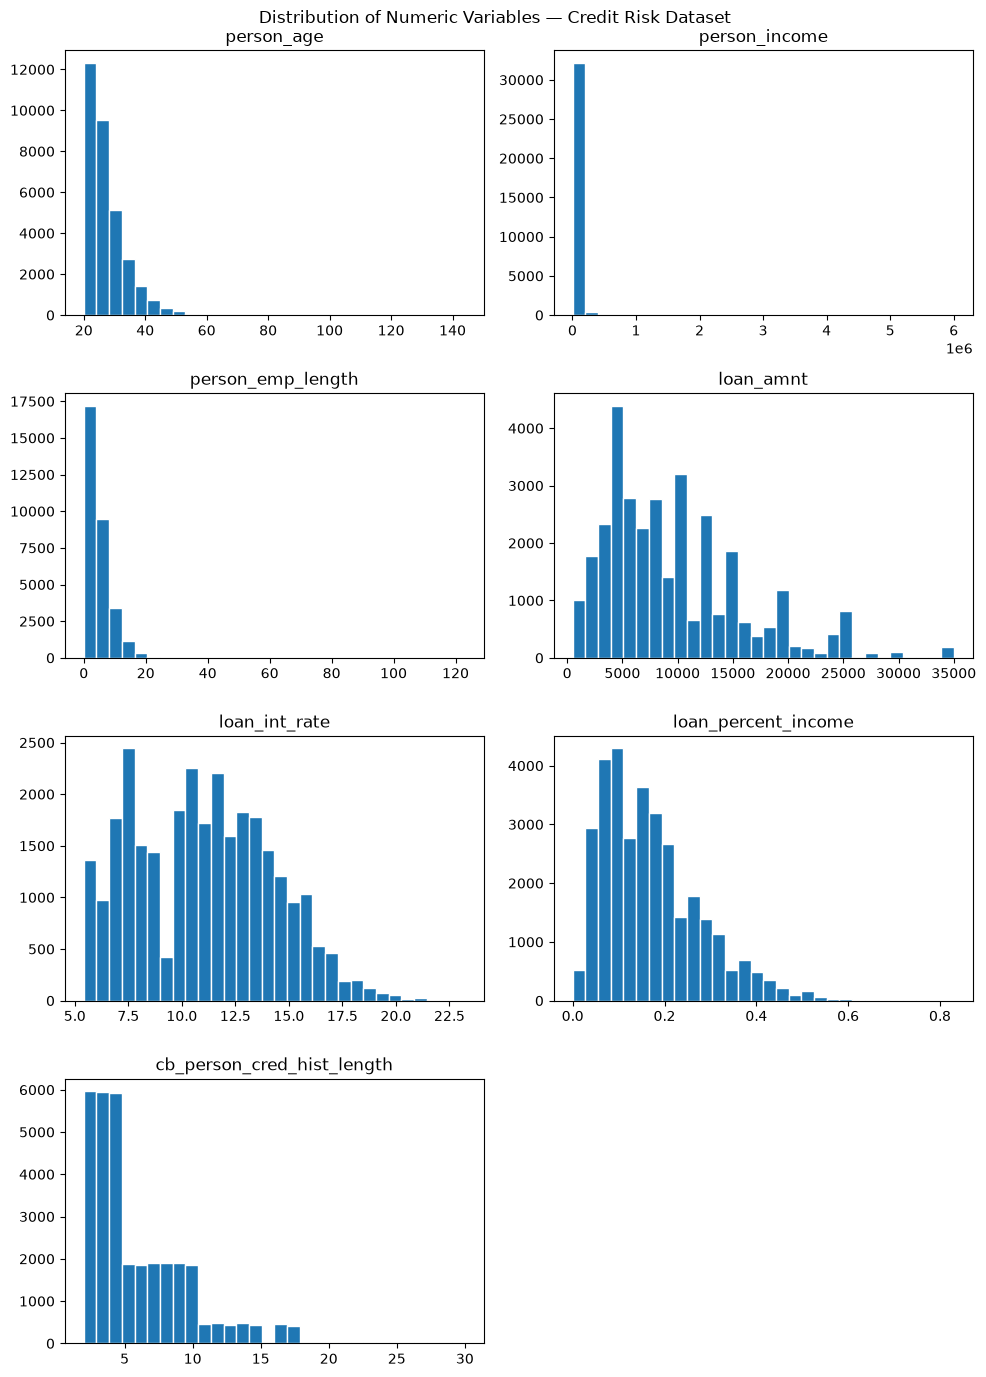

In [7]:
# Draw one histogram per numeric variable and use the column names as individual subplot titles.
axes = df[numeric_vars].hist(
    bins=30,
    figsize=(10, 14),
    layout=(4, 2),
    grid=False,
    edgecolor="white"
)

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Distribution of Numeric Variables — Credit Risk Dataset")
plt.tight_layout()
plt.show()

### Numeric distribution findings

Most numeric variables are concentrated at low values and have a long tail to the right. `person_age` is concentrated between about 20 and 40 years, `person_emp_length` between 0 and about 15 years, and `loan_percent_income` mostly below 0.4, with its most frequent values around 0.1. `cb_person_cred_hist_length` has a stepped shape, with most records at the shortest credit histories (about 2 to 4 years) and clearly fewer at longer ones. `loan_amnt` is also right-skewed, with irregular bars and peaks at round amounts such as 5,000, 10,000 and 15,000. `loan_int_rate` is the exception: it has two groups of frequent values, one around 7.5% and another between about 10% and 13%, with a visible dip in between.

Three variables have axes stretched by a few extreme records: `person_age` reaches about 140 years, `person_emp_length` about 120 years, and `person_income` about 6 million, so almost all incomes fall in a single bar next to zero. These values are kept in the data, and the next figure adjusts the displayed range so the main shape of these three variables can be read.

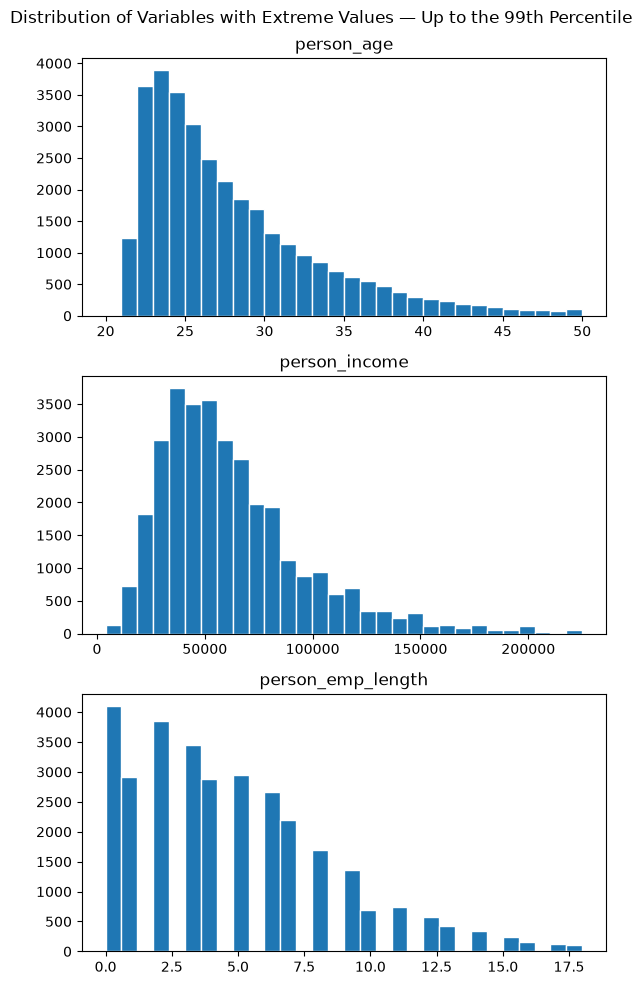

In [8]:
# Select the three variables with extreme values.
extreme_vars = df[["person_age", "person_income", "person_emp_length"]]

# Calculate the 99th percentile of each variable.
upper_limits = extreme_vars.quantile(0.99)

# Keep only values up to the 99th percentile in a copy used for plotting; larger values become missing and the histogram ignores them.
extreme_vars_trimmed = extreme_vars.where(extreme_vars <= upper_limits)

# Draw one histogram per variable, with bins computed only within the trimmed range.
axes = extreme_vars_trimmed.hist(
    bins=30,
    figsize=(6, 10),
    layout=(3, 1),
    grid=False,
    edgecolor="white"
)

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Distribution of Variables with Extreme Values — Up to the 99th Percentile")
plt.tight_layout()
plt.show()

### Adjusted-range findings

With the range limited to the 99th percentile, each variable shows a single main peak and a long tail to the right. `person_age` peaks at about 23 to 24 years and declines gradually. `person_income` peaks between about 40,000 and 55,000, with most records between 20,000 and 100,000. `person_emp_length` is highest at 0 years and decreases step by step. The records above the limits are not drawn here but remain in the dataset.

## 10. Explore categorical variables

Counting the records in each category shows how borrowers and loans are distributed across home ownership, loan purpose, loan grade, and previous defaults on file.

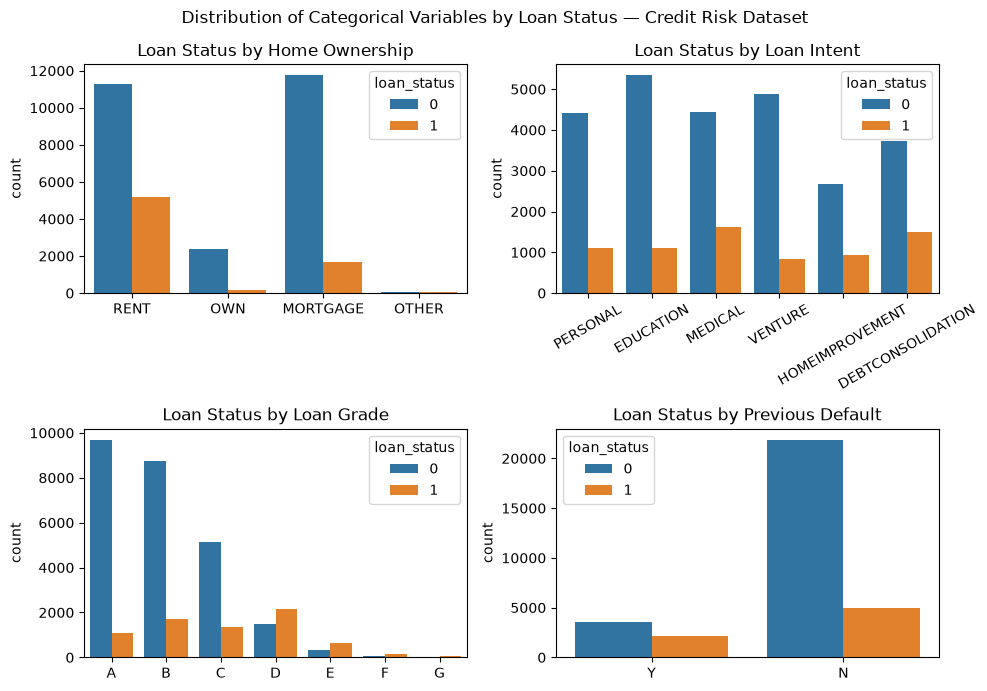

In [9]:
# Create a grid of subplots, one per categorical variable, so all distributions can be compared in a single figure.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Count loans by home ownership, split by loan status (0 = repaid, 1 = default), to see how defaults are distributed within each group.
sns.countplot(data=df, x="person_home_ownership", hue="loan_status", ax=axes[0, 0])
axes[0, 0].set_title("Loan Status by Home Ownership")

# Repeat for loan purpose; the labels are rotated because several category names are long.
sns.countplot(data=df, x="loan_intent", hue="loan_status", ax=axes[0, 1])
axes[0, 1].set_title("Loan Status by Loan Intent")
axes[0, 1].tick_params(axis="x", rotation=30)

# Repeat for loan grade, forcing the natural order from A to G instead of the order of appearance.
sns.countplot(x="loan_grade", data=df, hue="loan_status", order=["A", "B", "C", "D", "E", "F", "G"], ax=axes[1, 0])
axes[1, 0].set_title("Loan Status by Loan Grade")

# Repeat for the previous default on file recorded by the credit bureau.
sns.countplot(x="cb_person_default_on_file", data=df, hue="loan_status", ax=axes[1, 1])
axes[1, 1].set_title("Loan Status by Previous Default")

# Remove the x-axis labels because each subplot title already names the variable.
for ax in axes.ravel():
    ax.set_xlabel("")

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Distribution of Categorical Variables by Loan Status — Credit Risk Dataset")
plt.tight_layout()
plt.show()

### Categorical distribution findings

Most loans belong to borrowers who rent (about 16,500) or have a mortgage (about 13,500); `OWN` has far fewer and `OTHER` is barely visible. Loan purposes are fairly balanced, although `HOMEIMPROVEMENT` is noticeably smaller. The number of loans falls steadily from grade A (about 10,800) to grade G, which has almost no records, and in grades D to G the default bar is taller than the repaid bar, unlike in grades A to C. Most borrowers have no previous default on file, and among those with one, the default bar is more than half the size of the repaid bar. The next section measures these differences as default rates.

## 11. Compare default rates by category

The central question of this project is which borrower and loan characteristics are associated with default. For each categorical variable, this section compares the default rate of every category, calculated as the percentage of loans with `loan_status` = 1, against the overall default rate. The dashed line marks the default rate across all loans, used as a common reference for every variable. Categories above the line are associated with more defaults than average. The number of loans in each category is also reported, because a rate based on few loans is less reliable. These comparisons show associations, not causes.

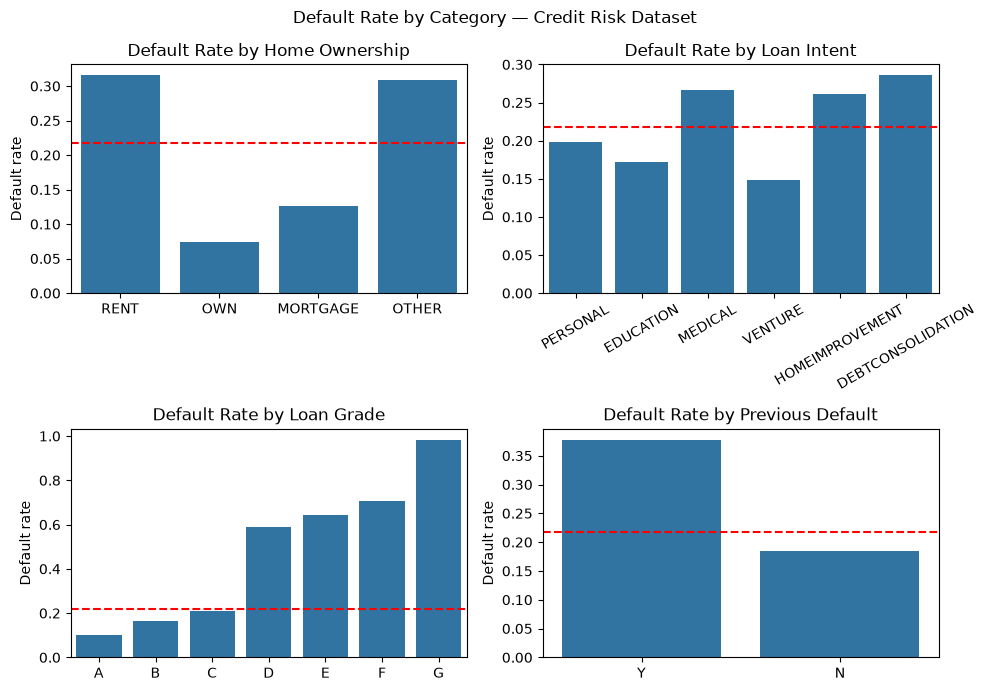

In [10]:
# Calculate the default rate across all loans, used as a common reference line in every subplot.
overall_default_rate = df["loan_status"].mean()

# Create a grid of subplots, one per categorical variable, so default rates can be compared in a single figure.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Plot the default rate by home ownership; since loan_status is 0 or 1, the bar height is the share of loans in default.
sns.barplot(data=df, x="person_home_ownership", y="loan_status", errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title("Default Rate by Home Ownership")

# Repeat for loan purpose; the labels are rotated because several category names are long.
sns.barplot(data=df, x="loan_intent", y="loan_status", errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Default Rate by Loan Intent")
axes[0, 1].tick_params(axis="x", rotation=30)

# Repeat for loan grade, forcing the natural order from A to G instead of the order of appearance.
sns.barplot(data=df, x="loan_grade", y="loan_status", order=["A", "B", "C", "D", "E", "F", "G"], errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title("Default Rate by Loan Grade")

# Repeat for the previous default on file recorded by the credit bureau.
sns.barplot(data=df, x="cb_person_default_on_file", y="loan_status", errorbar=None, ax=axes[1, 1])
axes[1, 1].set_title("Default Rate by Previous Default")

# Add the overall default rate as a dashed line and label the axes in every subplot.
for ax in axes.ravel():
    ax.axhline(overall_default_rate, color="red", linestyle="--")
    ax.set_xlabel("")
    ax.set_ylabel("Default rate")

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Default Rate by Category — Credit Risk Dataset")
plt.tight_layout()
plt.show()

### Default rate findings

Default rates differ across categories, and `loan_grade` shows the widest gap: rates stay below the overall rate (around 20%) for grades A to C, jump above 55% from grade D, and approach 100% for grade G. Renters (`RENT`) and `OTHER` default at about 31% to 32%, while homeowners (`OWN`) are at about 8% and `MORTGAGE` at about 12%. Borrowers with a previous default on file (`Y`) default at about 38%, against about 18% for those without one. Loan purpose shows a narrower spread, from about 15% (`VENTURE`) to about 29% (`DEBTCONSOLIDATION`), with `MEDICAL` and `HOMEIMPROVEMENT` also above the overall rate. The rates for `OTHER` and for grade G rest on very few loans, so they should be read with caution.

## 12. Compare numeric variables by loan status

The previous section compared default rates across categories. This section compares the distribution of each numeric variable between repaid loans (`loan_status` = 0) and loans in default (`loan_status` = 1), to see which variables differ most between the two groups. Extreme values are hidden in the boxplots so the boxes remain readable; they are kept in the data.

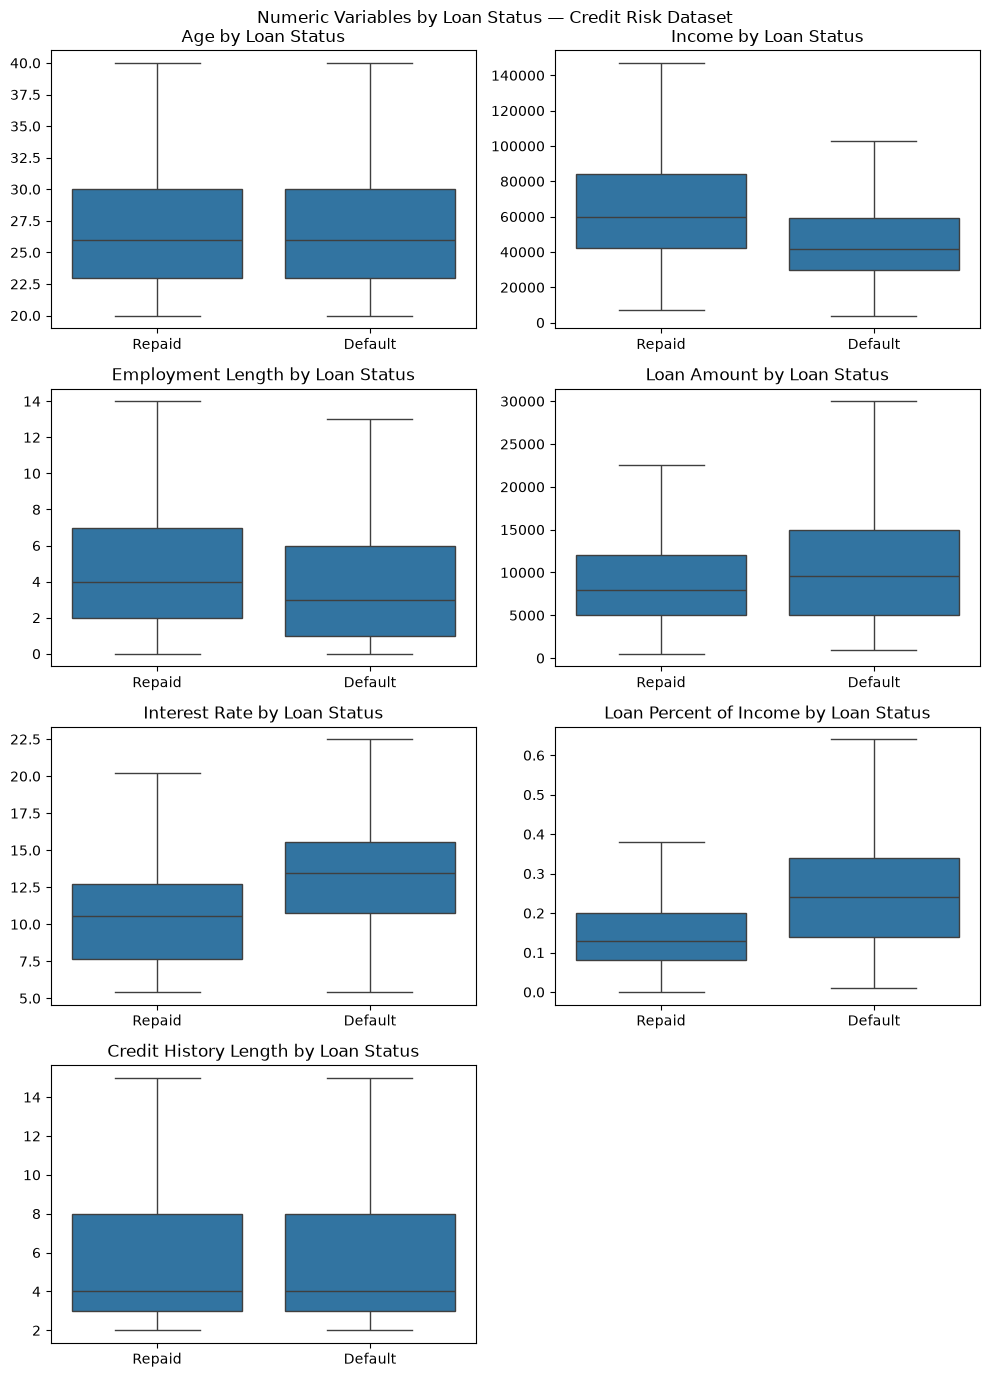

In [11]:
# Create a grid of subplots, one per numeric variable, so repaid loans (0) and loans in default (1) can be compared in a single figure.
fig, axes = plt.subplots(4, 2, figsize=(10, 14))

# Compare borrower age by loan status; extreme values are hidden in every boxplot so the boxes stay readable (they remain in the data).
sns.boxplot(data=df, x="loan_status", y="person_age", showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title("Age by Loan Status")

# Repeat for annual income.
sns.boxplot(data=df, x="loan_status", y="person_income", showfliers=False, ax=axes[0, 1])
axes[0, 1].set_title("Income by Loan Status")

# Repeat for employment length.
sns.boxplot(data=df, x="loan_status", y="person_emp_length", showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Employment Length by Loan Status")

# Repeat for loan amount.
sns.boxplot(data=df, x="loan_status", y="loan_amnt", showfliers=False, ax=axes[1, 1])
axes[1, 1].set_title("Loan Amount by Loan Status")

# Repeat for interest rate.
sns.boxplot(data=df, x="loan_status", y="loan_int_rate", showfliers=False, ax=axes[2, 0])
axes[2, 0].set_title("Interest Rate by Loan Status")

# Repeat for the loan amount as a share of income.
sns.boxplot(data=df, x="loan_status", y="loan_percent_income", showfliers=False, ax=axes[2, 1])
axes[2, 1].set_title("Loan Percent of Income by Loan Status")

# Repeat for credit history length.
sns.boxplot(data=df, x="loan_status", y="cb_person_cred_hist_length", showfliers=False, ax=axes[3, 0])
axes[3, 0].set_title("Credit History Length by Loan Status")

# Hide the empty box left in the grid, since there are 7 variables and 8 boxes.
axes[3, 1].set_visible(False)

# Remove the axis labels because each subplot title already names the variable, and replace 0 and 1 with readable labels.
for ax in axes.ravel():
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Repaid", "Default"])

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Numeric Variables by Loan Status — Credit Risk Dataset")
plt.tight_layout()
plt.show()

### Numeric variables and default findings

Three variables separate repaid loans from defaults. Loans in default have a higher interest rate, a higher loan amount relative to income, and lower borrower income. `person_emp_length` and `loan_amnt` show smaller differences with clearly overlapping boxes: defaults have a slightly shorter employment length and a slightly higher loan amount. `person_age` and `cb_person_cred_hist_length` look practically identical in both groups. Extreme values are hidden in the boxplots but kept in the data.

## 13. Examine correlations

The correlation matrix summarizes how strongly each pair of numeric variables moves together, including `loan_status`. Values close to 1 or -1 indicate a strong linear relationship, and values close to 0 indicate little or none.

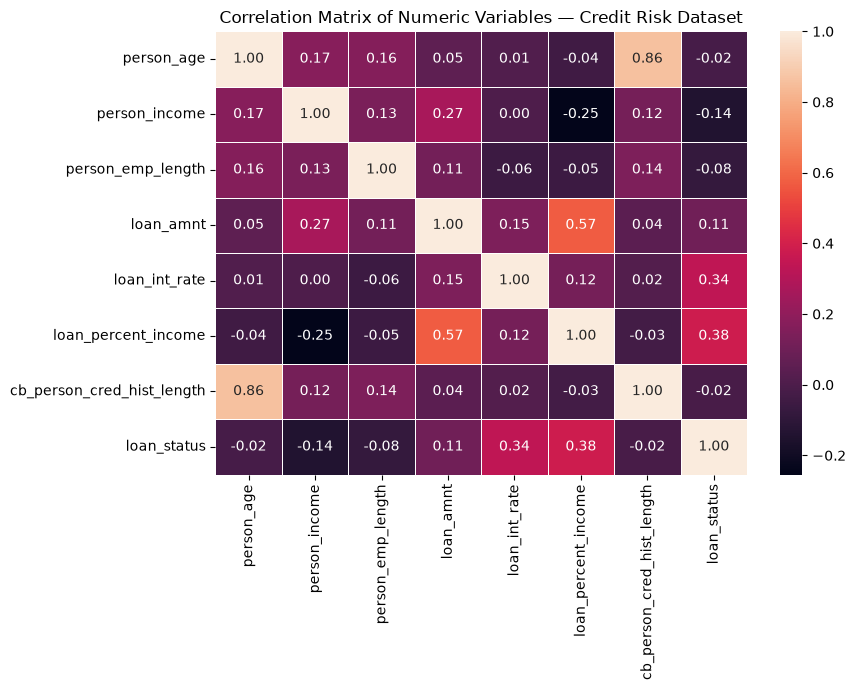

In [12]:
# Calculate the correlation matrix of the numeric variables, including loan_status, to see how strongly each pair moves together.
corr_matrix = df[numeric_vars + ["loan_status"]].corr()

# Draw the matrix as a heatmap with the correlation values written in each cell.
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, linewidths=0.5, fmt=".2f")

# Add a title and adjust spacing so the labels are not cut off.
plt.title("Correlation Matrix of Numeric Variables — Credit Risk Dataset")
plt.tight_layout()
plt.show()

### Correlation findings

No numeric variable has a strong linear relationship with `loan_status`. The highest correlations with default are `loan_percent_income` (0.38) and `loan_int_rate` (0.34), followed by weaker ones for `person_income` (-0.14) and `loan_amnt` (0.11). Among the predictors, `person_age` and `cb_person_cred_hist_length` are strongly correlated with each other (0.86), so they carry largely the same information, and `loan_amnt` and `loan_percent_income` are moderately correlated (0.57).

## 14. Conclusions and next steps

### Key findings

- **Loan grade:** default is strongly associated with the loan grade. Grades A to C stay below the overall default rate (about 22%), while grades D to G exceed 55%.
- **Other categories:** renters, borrowers with a previous default on file, and loans for debt consolidation, medical expenses or home improvement default more than average.
- **Numeric variables:** defaulted loans show higher interest rates, a larger loan amount relative to income, and lower borrower income. Age and credit history length look similar in both groups.
- **Correlations:** no numeric variable has a strong linear relationship with default.

### Data-quality issues

- **Missing values:** `person_emp_length` (2.75%) and `loan_int_rate` (9.56%).
- **Implausible values:** ages up to 144 years, employment lengths up to 123 years, and an income of 6,000,000.
- **Small categories:** `OTHER` home ownership and grade G have very few loans, so their default rates are less reliable.

### Next steps

- Decide how to treat missing and implausible values, and document how many records each decision affects.
- Check the dataset documentation for how the variables were produced, and whether `loan_grade` and `loan_int_rate` are set by the lender's own risk assessment, since that would limit their use as predictors.
- Build a baseline default-prediction model, which this exploratory analysis prepares.

### Final note

This notebook is an exploratory analysis, not a lending decision tool or a causal study. Its conclusions are limited to the data available in the dataset.